# Phishing Detection Model Training
This notebook trains a high-accuracy phishing detection model using `phishing_URL_Dataset.csv`.
It specifically drops data-leakage features to prevent artificial 100% accuracy and produce a realistic model.

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the dataset
df = pd.read_csv('phishing_URL_Dataset.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [4]:
# Data preprocessing
# Drop non-feature columns like FILENAME and URL
# 'label' column is the target (0 for legitimate, 1 for phishing)

# We must also drop categorical string columns like 'Domain', 'TLD', 'Title'
# AND drop data leakage features that are causing artificial 100% accuracy 
columns_to_drop = [
    'FILENAME', 'URL', 'label', 'URLSimilarityIndex', 'URLLength', 'NoOfLettersInURL', 
    'HasSocialNet', 'HasCopyrightInfo', 'HasDescription', 'IsHTTPS', 'DomainTitleMatchScore', 
    'HasSubmitButton', 'IsResponsive', 'URLTitleMatchScore', 'SpacialCharRatioInURL', 
    'HasHiddenFields', 'HasFavicon', 'URLCharProb', 'CharContinuationRate', 'HasTitle', 
    'DegitRatioInURL', 'Robots', 'NoOfJS', 'LetterRatioInURL', 'Pay', 'NoOfOtherSpecialCharsInURL', 
    'NoOfSelfRef', 'DomainLength', 'NoOfImage', 'LineOfCode', 'NoOfExternalRef', 'NoOfiFrame', 
    'Bank', 'NoOfDegitsInURL', 'NoOfQMarkInURL', 'HasExternalFormSubmit', 'HasPasswordField', 
    'NoOfEmptyRef', 'Crypto', 'TLDLegitimateProb', 'TLDLength', 'NoOfEqualsInURL', 
    'NoOfSelfRedirect', 'NoOfCSS'
]

# Identify and drop string/categorical columns automatically
df_features = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
categorical_cols = df_features.select_dtypes(include=['object']).columns.tolist()
if categorical_cols:
    print(f"Dropping categorical columns: {categorical_cols}")

X = df_features.drop(columns=categorical_cols)
y = df['label']

# Handle any potential missing values by filling with 0
X.fillna(0, inplace=True)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training Set: {X_train.shape}")
print(f"Testing Set: {X_test.shape}")

Dropping categorical columns: ['Domain', 'TLD', 'Title']
Training Set: (188636, 9)
Testing Set: (47159, 9)


In [5]:
# Initialize individual models
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
lgbm_model = LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42)

# Create an Ensemble (Voting Classifier)
ensemble_model = VotingClassifier(
    estimators=[
        ('rf', rf_model), 
        ('xgb', xgb_model),
        ('lgbm', lgbm_model)
    ], 
    voting='soft'  # 'soft' uses probabilities for better accuracy
)

print("Training Hybrid Ensemble Model (RF + XGBoost + LightGBM)...")
ensemble_model.fit(X_train, y_train)


Training Hybrid Ensemble Model (RF + XGBoost + LightGBM)...
[LightGBM] [Info] Number of positive: 107880, number of negative: 80756
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005673 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 461
[LightGBM] [Info] Number of data points in the train set: 188636, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.571895 -> initscore=0.289587
[LightGBM] [Info] Start training from score 0.289587


,estimators,"[('rf', ...), ('xgb', ...), ...]"
,voting,'soft'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1


Accuracy: 93.71%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.88      0.92     20189
           1       0.92      0.98      0.95     26970

    accuracy                           0.94     47159
   macro avg       0.94      0.93      0.93     47159
weighted avg       0.94      0.94      0.94     47159



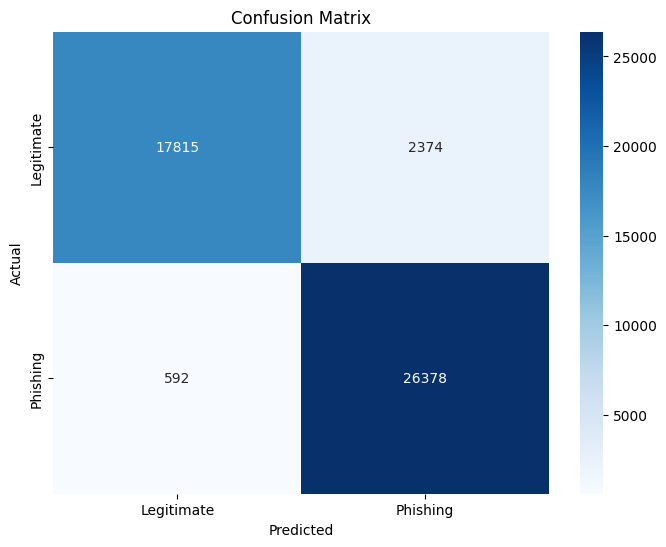

In [6]:
# Evaluate the model
y_pred = ensemble_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legitimate', 'Phishing'], yticklabels=['Legitimate', 'Phishing'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [7]:
# Feature Importance from Ensemble
rf_fitted = ensemble_model.estimators_[0]
xgb_fitted = ensemble_model.estimators_[1]
feature_importance = (rf_fitted.feature_importances_ + xgb_fitted.feature_importances_) / 2

features = X_train.columns.tolist()
importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Important Features (Hybrid Ensemble Average):")
print(importance_df.head(10))

# Save the model and feature names
model_filename = 'model.pkl'
features_filename = 'features.pkl'

joblib.dump(ensemble_model, model_filename)
joblib.dump(features, features_filename)

print(f"\nSaved ensemble model to {model_filename}")
print(f"Saved feature names to {features_filename}")


Top 10 Important Features (Hybrid Ensemble Average):
              Feature  Importance
6   LargestLineLength    0.680510
1       NoOfSubDomain    0.132048
0          IsDomainIP    0.054291
5  NoOfAmpersandInURL    0.052008
8           NoOfPopup    0.049047
7     NoOfURLRedirect    0.031470
2      HasObfuscation    0.000269
3  NoOfObfuscatedChar    0.000214
4    ObfuscationRatio    0.000144

Saved ensemble model to model.pkl
Saved feature names to features.pkl
